In [1]:
# Core libraries
import numpy as np
import pandas as pd
from itertools import combinations

# Plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FuncFormatter
import seaborn as sns
import plotly.graph_objects as go
from IPython.display import clear_output

# Modeling and stats
from scipy.optimize import curve_fit
from scipy.integrate import simpson
from scipy.stats import friedmanchisquare, wilcoxon, mannwhitneyu
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.anova import AnovaRM

In [2]:
# Read in the data
raw_data=pd.read_csv("007_CLEANED_$1000_Combining_Effects_Effort_and_Delay_October 28, 2025_20.02.csv")
data=raw_data.copy()
data['pid'] = [f"P{num}" for num in range(len(data))]

In [3]:
data

,ResponseId,Prolific ID,0_3_$500,0_3_$750,0_3_$250,0_3_$625,0_3_$875,0_3_$125,0_3_$375,0_3_$563,...,260_0_$969,260_0_$31,260_0_$94,260_0_$156,260_0_$219,260_0_$281,260_0_$344,260_0_$406,260_0_$469,pid
0,R_5QALHR4V6c87yQi,628f572a2d1304a34b9e1a37,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Getting $1000 in 5 years,P0
1,R_61qsPiSvdeyXBnz,60284b049e884437b220b172,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,Immediately getting $156,NaN,NaN,NaN,NaN,NaN,P1
2,R_3F4JdRkirwse5P0,5934a676e7866d0001618b81,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,Immediately getting $156,NaN,NaN,NaN,NaN,NaN,P2
3,R_5AmoWMKHriioc49,6294cced417fa0a733ba14a4,Getting $1000 after climbing 3 flights,Getting $750 without climbing flights,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,NaN,...,NaN,NaN,Getting $1000 in 5 years,NaN,NaN,NaN,NaN,NaN,NaN,P3
4,R_5eUuvubqb7JUD6H,5b73a9b309cd2c0001edb357,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,Immediately getting $156,NaN,NaN,NaN,NaN,NaN,P4
5,R_6rPA2xwPiTYPr3V,651c4484ba17050f6b716614,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,Immediately getting $156,NaN,NaN,NaN,NaN,NaN,P5
6,R_7r0nWN61EiSWRdM,6726c172ae503d706acdc74b,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,Immediately getting $31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,P6
7,R_77eaQ6imOeaDCAu,6604cdce9c02df4997ec8b68,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,P7
8,R_122TOu0bXalJCkC,60bd3949b6f6d9c3453e8def,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,Immediately getting $31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,P8
9,R_5K8vH6msFsqCKYx,5c36e40e299f82000103ce0a,Getting $1000 after climbing 3 flights,Getting $1000 after climbing 3 flights,NaN,NaN,Getting $1000 after climbing 3 flights,NaN,NaN,NaN,...,NaN,NaN,NaN,Immediately getting $156,NaN,NaN,NaN,NaN,NaN,P9


In [4]:
# Create a dict connecting PID to other IDs in case needed later
id_dict = pd.DataFrame(data[['pid', 'ResponseId', 'Prolific ID']])
data= data.drop(['ResponseId', 'Prolific ID'], axis=1)

In [5]:
# Convert the data from wide to long
df = data.melt(id_vars=['pid'])
df.columns = ['pid', 'question', 'choice']

In [6]:
df

,pid,question,choice
0,P0,0_3_$500,Getting $1000 after climbing 3 flights
1,P1,0_3_$500,Getting $1000 after climbing 3 flights
2,P2,0_3_$500,Getting $1000 after climbing 3 flights
3,P3,0_3_$500,Getting $1000 after climbing 3 flights
4,P4,0_3_$500,Getting $1000 after climbing 3 flights
...,...,...,...
17820,P20,260_0_$469,Getting $1000 in 5 years
17821,P21,260_0_$469,NaN
17822,P22,260_0_$469,NaN
17823,P23,260_0_$469,NaN


In [7]:
# Basic cleaning
df = df.dropna()
df = df.drop_duplicates(subset=['pid', 'question']).reset_index(drop=True)

# Extract the probability value from the string text and add odds against col
df['delay'] = [int(val.split("_")[0]) for val in df['question']]
# df['probability'] = df['probability']/100
# df['odds_against'] = (1-(df['probability']))/(df['probability'])
# prob_odds_dict = dict(zip(df['odds_against'], df['probability'])) # Dict to use later

# Extract out effort and money values from the string texts
df['effort'] = [float(val.split("_")[1]) for val in df['question']]
df['final_money'] = [float(val.split("_")[2].replace("$", "")) for val in df['question']]

# Final check to avoid duplicates if they exist for some reason
df = df.drop_duplicates(subset=['pid', 'delay', 'effort'], keep='last').reset_index(drop=True)

In [8]:
# Calculate final indifference point values based on last choice with final money
ips = []

for i in range(len(df)):
    if "100%" in df['choice'][i]:
        ips.append(df['final_money'][i]-1.56)
    else:
        ips.append(df['final_money'][i]+1.56)

df['indiff_point'] = ips

In [9]:
# Function for calculating AUC
def normalized_trapezoidal_auc(x, y, x_min=None, x_max=None, y_min=None, y_max=None):
    """
    Compute trapezoidal AUC after normalizing using global bounds.
    Ensures all AUC values fall between 0 and 1.
    """
    if len(x) < 2:
        return np.nan

    x = np.array(x)
    y = np.array(y)
    sorted_idx = np.argsort(x)
    x = x[sorted_idx]
    y = y[sorted_idx]

    # Use provided bounds or default to range of x/y
    x_min = x.min() if x_min is None else x_min
    x_max = x.max() if x_max is None else x_max
    y_min = y.min() if y_min is None else y_min
    y_max = y.max() if y_max is None else y_max

    # Normalize to [0, 1] using known scale
    if x_max != x_min:
        x_norm = (x - x_min) / (x_max - x_min)
    else:
        x_norm = x
    if y_max != y_min:
        y_norm = (y - y_min) / (y_max - y_min)
    else:
        y_norm = y

    # Apply trapezoidal rule
    auc = 0.0
    for i in range(len(x_norm) - 1):
        dx = x_norm[i + 1] - x_norm[i]
        avg_height = (y_norm[i] + y_norm[i + 1]) / 2
        auc += dx * avg_height
    return auc

In [10]:
# Initialize result containers
auc_delay_as_func_effort = []
auc_effort_as_func_delay = []


for part in df['pid'].unique():
    part_df = (
        df[df['pid'] == part]
        .drop_duplicates(subset=['delay', 'effort'], keep='last')
        .reset_index(drop=True)
    )

    # --- AUC 1: Indifference as a Function of Effort (within fixed delay) ---
    for delay in part_df['delay'].unique():
        temp = part_df[part_df['delay'] == delay]
        if temp.shape[0] >= 2:
            grouped = temp.groupby('effort')['indiff_point'].mean().sort_index()
            x = grouped.index.values.astype(float)   # effort
            y = grouped.values.astype(float)         # indifference points (0-100)

            auc = normalized_trapezoidal_auc(x, y, x_min=3, x_max=40, y_min=0, y_max=1000)

            auc_delay_as_func_effort.append({
                'pid': part,
                'delay': float(delay),
                'auc_delay_as_func_effort': auc
            })

    # --- AUC 2: Indifference as a Function of Delay (within fixed effort) ---
    # Choose x-axis: delay
    for eff in part_df['effort'].unique():
        temp = part_df[part_df['effort'] == eff]
        if temp.shape[0] >= 2:
            grouped = temp.groupby('delay')['indiff_point'].mean().sort_index()
            x = grouped.index.values.astype(float)   # odds_against (>=0)
            y = grouped.values.astype(float)         # indifference points (0-100)

            # Set x bounds to your observed/global scale.
            # If you truly want x in [0,9], keep it; otherwise use data-driven bounds.
            auc = normalized_trapezoidal_auc(x, y, x_min=0, x_max=9, y_min=0, y_max=1000)

            auc_effort_as_func_delay.append({
                'pid': part,
                'effort': float(eff),
                'auc_effort_as_func_delay': auc
            })

auc_delay_df = pd.DataFrame(auc_delay_as_func_effort)
auc_eff_df  = pd.DataFrame(auc_effort_as_func_delay)



In [11]:
print("Delay", auc_delay_df['pid'].nunique())
print("Effort", auc_eff_df['pid'].nunique())

Delay 25
Effort 25


In [12]:
# Functions for comparisons
def run_friedman_and_posthoc(df, subject_col, effort_col, metric_col, alpha=0.05):
    pivoted = df.pivot(index=subject_col, columns=effort_col, values=metric_col).dropna()

    if pivoted.shape[1] < 2: #what does this mean?
        return None, None, []

    stat, p = friedmanchisquare(*[pivoted[col] for col in pivoted.columns])

    corrected = []
    if p < alpha:
        posthoc = []
        for c1, c2 in combinations(pivoted.columns, 2):
            w_stat, w_p = wilcoxon(pivoted[c1], pivoted[c2])
            posthoc.append((c1, c2, w_stat, w_p))

        corrected = [(a, b, w, min(pv * len(posthoc), 1.0)) for a, b, w, pv in posthoc]

    return stat, p, corrected

def print_friedman_and_posthoc(df, subject_col, effort_col, metric_col, metric_label, alpha=0.05, posthoc_trigger=0.2):
    pivoted = df.pivot(index=subject_col, columns=effort_col, values=metric_col).dropna()

    if pivoted.shape[1] < 2:
        print(f"\nNot enough effort levels for {metric_label}")
        return

    stat, p = friedmanchisquare(*[pivoted[col] for col in pivoted.columns])
    print(f"\n=== {metric_label} ===")
    print(f"Friedman test statistic: {stat:.3f}, p-value: {p:.5f}")

    if p < posthoc_trigger:
        print("Post-hoc Wilcoxon tests with Bonferroni correction:")
        posthoc_results = []
        for c1, c2 in combinations(pivoted.columns, 2):
            w_stat, w_p = wilcoxon(pivoted[c1], pivoted[c2])
            posthoc_results.append((c1, c2, w_stat, w_p))

        corrected = [(a, b, w, min(pv * len(posthoc_results), 1.0)) for a, b, w, pv in posthoc_results]
        for a, b, w, corr_p in corrected:
            sig = "*" if corr_p < alpha else "n.s."
            print(f"  {a} vs. {b}: W={w:.5f}, corrected p = {corr_p:.5f} {sig}")
    else:
        print("No evidence of differences between effort levels (per threshold).")

def print_rm_anova(df, subject_col, within_col, dv_col, dv_label):
    print(f"\n=== Repeated Measures ANOVA: {dv_label} ===")
    try:
        aov = AnovaRM(df, depvar=dv_col, subject=subject_col, within=[within_col]).fit()
        print(aov.summary())
    except Exception as e:
        print(f"Could not run ANOVA for {dv_label}: {e}")


In [13]:
df

,pid,question,choice,delay,effort,final_money,indiff_point
0,P3,0_3_$719,Getting $719 without climbing flights,0,3.0,719.0,720.56
1,P8,0_3_$906,Getting $906 without climbing flights,0,3.0,906.0,907.56
2,P9,0_3_$906,Getting $906 without climbing flights,0,3.0,906.0,907.56
3,P20,0_3_$906,Getting $906 without climbing flights,0,3.0,906.0,907.56
4,P0,0_3_969,Getting $1000 after climbing 3 flights,0,3.0,969.0,970.56
...,...,...,...,...,...,...,...
570,P14,260_0_$219,Getting $1000 in 5 years,260,0.0,219.0,220.56
571,P22,260_0_$219,Getting $1000 in 5 years,260,0.0,219.0,220.56
572,P0,260_0_$469,Getting $1000 in 5 years,260,0.0,469.0,470.56
573,P15,260_0_$469,Getting $1000 in 5 years,260,0.0,469.0,470.56


In [14]:
# Get group indifference points using mean
group_fit = df.groupby(by=['delay', 'effort'])['indiff_point'].mean().unstack().reset_index()
group_fit = group_fit.melt(id_vars=['delay'])
group_fit.columns = ['delay', 'effort', 'indiff_point']
group_fit.fillna(0, inplace=True)

,delay,effort,indiff_point
0,0,0.0,0.00
1,1,0.0,925.48
2,4,0.0,792.88
3,26,0.0,602.96
4,52,0.0,497.92
5,260,0.0,315.32
6,0,3.0,898.00
7,1,3.0,885.48
8,4,3.0,752.84
9,26,3.0,597.88


In [15]:
df['pid'].nunique()

25

In [16]:
df

,pid,question,choice,delay,effort,final_money,indiff_point
0,P3,0_3_$719,Getting $719 without climbing flights,0,3.0,719.0,720.56
1,P8,0_3_$906,Getting $906 without climbing flights,0,3.0,906.0,907.56
2,P9,0_3_$906,Getting $906 without climbing flights,0,3.0,906.0,907.56
3,P20,0_3_$906,Getting $906 without climbing flights,0,3.0,906.0,907.56
4,P0,0_3_969,Getting $1000 after climbing 3 flights,0,3.0,969.0,970.56
...,...,...,...,...,...,...,...
570,P14,260_0_$219,Getting $1000 in 5 years,260,0.0,219.0,220.56
571,P22,260_0_$219,Getting $1000 in 5 years,260,0.0,219.0,220.56
572,P0,260_0_$469,Getting $1000 in 5 years,260,0.0,469.0,470.56
573,P15,260_0_$469,Getting $1000 in 5 years,260,0.0,469.0,470.56



=== Effort AUC ===
Friedman test statistic: 5.368, p-value: 0.14676
Post-hoc Wilcoxon tests with Bonferroni correction:
  0.0 vs. 3.0: W=150.00000, corrected p = 1.00000 n.s.
  0.0 vs. 11.0: W=87.00000, corrected p = 0.25290 n.s.
  0.0 vs. 40.0: W=67.00000, corrected p = 0.05293 n.s.
  3.0 vs. 11.0: W=76.00000, corrected p = 0.35599 n.s.
  3.0 vs. 40.0: W=73.00000, corrected p = 0.16684 n.s.
  11.0 vs. 40.0: W=81.00000, corrected p = 1.00000 n.s.

=== Delay AUC ===
Friedman test statistic: 92.898, p-value: 0.00000
Post-hoc Wilcoxon tests with Bonferroni correction:
  0.0 vs. 1.0: W=68.00000, corrected p = 0.16370 n.s.
  0.0 vs. 4.0: W=146.00000, corrected p = 1.00000 n.s.
  0.0 vs. 26.0: W=53.00000, corrected p = 0.03383 *
  0.0 vs. 52.0: W=24.00000, corrected p = 0.00291 *
  0.0 vs. 260.0: W=1.00000, corrected p = 0.00021 *
  1.0 vs. 4.0: W=30.00000, corrected p = 0.00910 *
  1.0 vs. 26.0: W=0.00000, corrected p = 0.00027 *
  1.0 vs. 52.0: W=0.00000, corrected p = 0.00027 *
  1.0 vs.

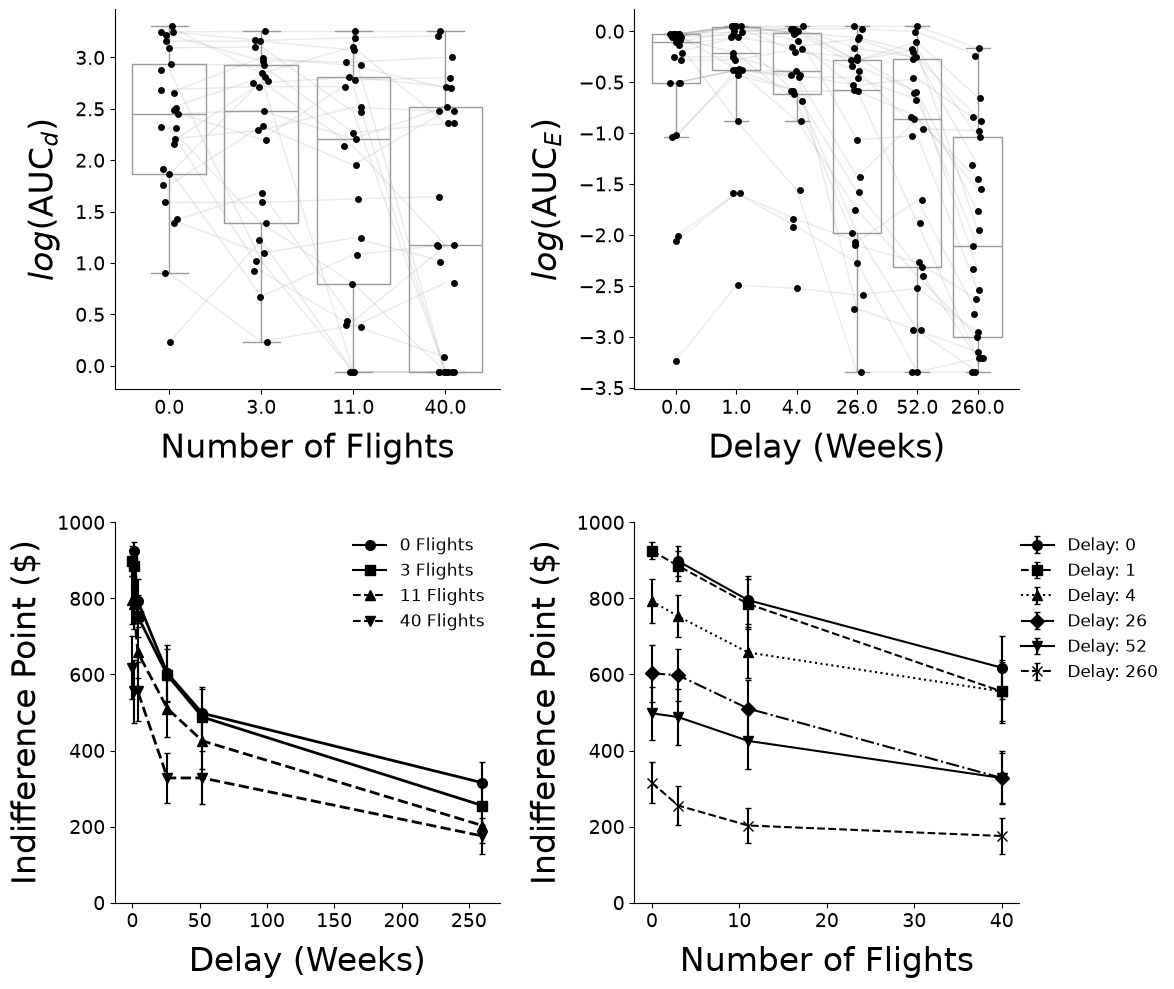

In [17]:



# Define marker and line styles per effort level
effort_styles = {
    0:  {'marker': 'o', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '-',  'linecolor': 'black'},
    3:  {'marker': 's', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '-',  'linecolor': 'black'},
    11: {'marker': '^', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '--', 'linecolor': 'black'},
    40: {'marker': 'v', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '--', 'linecolor': 'black'}
}
effort_levels = sorted(df['effort'].unique())
delay_levels = sorted(df['delay'].unique())
# Plot figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))


# Top-left: Effort AUC as a function of Effort (with within-subject lines)
ax = axes[0, 0]

x_vals = auc_eff_df['effort']
y_vals = np.log(auc_eff_df['auc_effort_as_func_delay'])

sns.boxplot(
    x=x_vals,
    y=y_vals,
    color=(1, 1, 1, 0.05),
    ax=ax,
    showfliers=False
)
sns.stripplot(
    x=x_vals,
    y=y_vals,
    color='k',
    ax=ax
)


# Within-subject spaghetti lines
tmp = auc_eff_df.copy()
tmp['x'] = tmp['effort']
tmp['y'] = np.log(tmp['auc_effort_as_func_delay'])

x_order = sorted(tmp['x'].unique())
x_pos = {x: i for i, x in enumerate(x_order)}
tmp['x_pos'] = tmp['x'].map(x_pos)

for pid, g in tmp.groupby('pid'):
    g = g.sort_values('x_pos')
    ax.plot(
        g['x_pos'], g['y'],
        color='0.6', linewidth=1, alpha=0.2, zorder=2
    )

ax.set_xticks(range(len(x_order)))
ax.set_xticklabels([str(x) for x in x_order])

ax.set_ylabel(r'$log$(AUC$_d$)', fontsize=24, labelpad=10)
ax.set_xlabel('Number of Flights', fontsize=24, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.1f}'))
ax.tick_params(axis='both', labelsize=14)
sns.despine(ax=ax, top=True, right=True)


# Top-right: Delay AUC as a function of Delay (with within-subject lines)
ax = axes[0, 1]

# Base box + points
x_vals = auc_delay_df['delay'].round(2)
y_vals = np.log(auc_delay_df['auc_delay_as_func_effort'])

sns.boxplot(
    x=x_vals,
    y=y_vals,
    color=(1, 1, 1, 0.05),
    ax=ax,
    showfliers=False
)
sns.stripplot(
    x=x_vals,
    y=y_vals,
    color='k',
    ax=ax
)

# Within-subject spaghetti lines
tmp = auc_delay_df.copy()
tmp['x'] = tmp['delay'].round(2)
tmp['y'] = np.log(tmp['auc_delay_as_func_effort'])

x_order = sorted(tmp['x'].unique())
x_pos = {x: i for i, x in enumerate(x_order)}
tmp['x_pos'] = tmp['x'].map(x_pos)

for pid, g in tmp.groupby('pid'):
    g = g.sort_values('x_pos')
    ax.plot(
        g['x_pos'], g['y'],
        color='0.6', linewidth=1, alpha=0.2, zorder=2
    )

# Ensure ticks match the numeric delay labels
ax.set_xticks(range(len(x_order)))
ax.set_xticklabels([str(x) for x in x_order])

ax.set_ylabel(r'$log$(AUC$_E$)', fontsize=24, labelpad=10)
ax.set_xlabel('Delay (Weeks)', fontsize=24, labelpad=10)
ax.tick_params(axis='both', labelsize=14)
sns.despine(ax=ax, top=True, right=True)


# Bottom-left: Indiff as a function of Delay
ax = axes[1, 0]
legend_elements = []

for eff in effort_levels:
    temp_df = df[df['effort'] == eff]
    grouped = temp_df.groupby('delay')['indiff_point']

    delay_vals = grouped.mean().index.to_numpy()
    indiff_mean = grouped.mean().to_numpy()

    counts = grouped.count()
    sem = (grouped.std(ddof=1) / np.sqrt(counts)).fillna(0).to_numpy()

    # sort so lines connect in x-order
    order = np.argsort(delay_vals)
    delay_vals = delay_vals[order]
    indiff_mean = indiff_mean[order]
    sem = sem[order]

    style = effort_styles.get(
        eff,
        {'marker': 'o', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '-', 'linecolor': 'black'}
    )

    ax.errorbar(
        delay_vals, indiff_mean, yerr=sem,
        fmt=style['marker'],
        markerfacecolor=style['facecolor'],
        markeredgecolor=style['edgecolor'],
        linestyle=style['linestyle'],
        color=style['linecolor'],
        ecolor=style['edgecolor'],
        capsize=2, elinewidth=1.5, markersize=7, linewidth=2
    )

    legend_elements.append(Line2D(
        [0], [0],
        marker=style['marker'],
        markerfacecolor=style['facecolor'],
        markeredgecolor=style['edgecolor'],
        linestyle=style['linestyle'],
        color=style['linecolor'],
        label=f"{int(eff)} Flights",
        markersize=7
    ))

ax.set_xlabel("Delay (Weeks)", fontsize=24, labelpad=10)
ax.set_ylabel("Indifference Point ($)", fontsize=24, labelpad=10)
ax.tick_params(axis='both', labelsize=14)
ax.set_ylim(0, 1000)
ax.set_xscale('linear')
ax.legend(handles=legend_elements, frameon=False, fontsize=12)
sns.despine(ax=ax, top=True, right=True)


# Bottom-right: Indiff as a function of Effort
ax = axes[1, 1]
marker_shapes = ['o', 's', '^', 'D', 'v', 'x']
line_styles = ['-', '--', ':', '-.']
delay_styles = {
    delay: {
        'marker': marker_shapes[i % len(marker_shapes)],
        'facecolor': 'k',
        'edgecolor': 'black',
        'linestyle': line_styles[i % len(line_styles)],
        'linecolor': 'k'
    }
    for i, delay in enumerate(delay_levels)
}

for delay in delay_levels:
    temp_df = df[df['delay'] == delay]
    grouped = temp_df.groupby('effort')['indiff_point']

    effort_vals = grouped.mean().index.values
    indiff_mean = grouped.mean().values

    counts = grouped.count()
    sem = grouped.std(ddof=1) / np.sqrt(counts)

    style = delay_styles[delay]

    ax.errorbar(
        effort_vals, indiff_mean, yerr=sem,
        fmt=style['marker'],
        markerfacecolor=style['facecolor'],
        markeredgecolor=style['edgecolor'],
        linestyle=style['linestyle'],
        color=style['linecolor'],
        capsize=2, elinewidth=1.5, markersize=7,
        label=f"Delay: {round(delay, 2)}"
    )

ax.set_xlabel("Number of Flights", fontsize=24, labelpad=10)
ax.set_ylabel("Indifference Point ($)", fontsize=24, labelpad=10)
ax.tick_params(axis='both', labelsize=14)
ax.set_ylim(0, 1000)
ax.set_xscale('linear')
ax.legend(loc="upper right", bbox_to_anchor=(1.4, 1), frameon=False, fontsize=12)
sns.despine(ax=ax, top=True, right=True)

# Layout tweaks
plt.tight_layout()
plt.subplots_adjust(hspace=0.35, wspace=0.35)

# Run stats
print_friedman_and_posthoc(auc_eff_df, 'pid', 'effort', 'auc_effort_as_func_delay', 'Effort AUC')
print_friedman_and_posthoc(auc_delay_df, 'pid', 'delay', 'auc_delay_as_func_effort', 'Delay AUC') #check this - do i need to drop duplicates?

plt.show()


## Combined Effects Models

Let:

- $D$ = delay to receipt of reward
- $E$ = effort (e.g., number of flights)
- $A$ = reward amount / undiscounted value scale parameter



## Hyperboloid models of delay and effort (MG and Rachlin forms)

### 1. MG$_D$–MG$_E$ Additive

$$
V(D,E)=\frac{A}{(1+kD)^{s_{delay}}+(1+\gamma E)^{s_{eff}}}
$$

### 2. MG$_D$–MG$_E$ Multiplicative

$$
V(D,E)=\frac{A}{(1+kD)^{s_{delay}}\cdot(1+\gamma E)^{s_{eff}}}
$$

---

### 3. R$_D$–R$_E$ Additive

$$
V(D,E)=\frac{A}{\left(1+kD^{s_{delay}}\right)+\left(1+\gamma E^{s_{eff}}\right)}
$$

### 4. R$_D$–R$_E$ Multiplicative

$$
V(D,E)=\frac{A}{\left(1+kD^{s_{delay}}\right)\cdot\left(1+\gamma E^{s_{eff}}\right)}
$$

---

## Delay discounting + Power-law effort term

Define the power-law effort denominator term:

$$
D_E(E)=1+k_E E^{s_{par}}
$$

### 5. MG$_D$–P$_E$ Additive

$$
V(D,E)=\frac{A}{(1+kD)^{s_{delay}}+\left(1+k_E E^{s_{par}}\right)}
$$

### 6. R$_p$–P$_E$ Additive

$$
V(D,E)=\frac{A}{\left(1+kD^{s_{delay}}\right)+\left(1+k_E E^{s_{par}}\right)}
$$

---

## Delay discounting + Multiplicative power-law effort factor

Define the multiplicative effort factor:

$$
F_E(E)=1-\gamma_e E^{s_e}
$$

### 7. MG$_D$–P$_E$ Multiplicative

$$
V(D,E)=\left(\frac{A}{(1+kD)^{s_{delay}}}\right)\cdot\left(1-\gamma_e E^{s_e}\right)
$$

### 8. R$_D$–P$_E$ Multiplicative

$$
V(D,E)=\left(\frac{A}{1+kD^{s_{delay}}}\right)\cdot\left(1-\gamma_e E^{s_e}\right)
$$

---

## GTD model combining delay and effort (delay weighting + effort cost)

### 9. GTD

$$
V(D,E)=\left[\max\left(D,\; A^{\alpha\, k(D)}-(k_E E)^{\beta}\right)\right]^{1/\alpha}
$$
## Parameter meanings

### Delay discounting parameters (MG form)
- $k$: delay discounting rate parameter  
- $s_{delay}$: delay discounting curvature/exponent  

### Effort discounting parameters (hyperboloid effort term)
- $\gamma$: effort discounting rate parameter  
- $s_{eff}$: effort discounting curvature/exponent  

### Additive power-law effort term parameters
- $k_E$: effort scaling parameter  
- $s_{par}$: effort exponent  

### Multiplicative power-law effort factor parameters
- $\gamma_e$: effort scaling parameter in multiplicative factor  
- $s_e$: effort exponent in multiplicative factor  

### GTD parameters
- $\alpha$: curvature/scaling parameter  
- $\kappa, \gamma$: Prelec delay-weighting parameters  
- $k_E$: effort scaling parameter  
- $\beta$: effort-cost exponent  


In [18]:
# AIC / AICc / BIC (Gaussian RSS form)
def _safe_sigma2_from_rss(rss: float, n: int, eps: float = 1e-12) -> float:
    return max(rss / max(n, 1), eps)

def compute_aic_from_rss(n: int, rss: float, k: int) -> float:
    sigma2 = _safe_sigma2_from_rss(rss, n)
    return n * np.log(sigma2) + 2 * k

def compute_aicc_from_rss(n: int, rss: float, k: int) -> float:
    aic = compute_aic_from_rss(n, rss, k)
    return aic + (2 * k * (k + 1)) / (n - k - 1) if n > (k + 1) else np.nan

def compute_bic_from_rss(n: int, rss: float, k: int) -> float:
    sigma2 = _safe_sigma2_from_rss(rss, n)
    return n * np.log(sigma2) + k * np.log(n)


# 1) Hyperboloid combined-effects models (MG + Rachlin) # does 0 = delay? 
def hyper_mg_delay(D, k, s_delay):
    return (1.0 + k * D) ** s_delay

def hyper_mg_eff(E, gamma, s_eff):
    return (1.0 + gamma * E) ** s_eff

def hyper_rach_delay(D, k, s_delay):
    return 1.0 + k * (D ** s_delay)

def hyper_rach_eff(E, gamma, s_eff):
    return 1.0 + gamma * (E ** s_eff)

def combined_mult(X, A, k, s_delay, gamma, s_eff, delay_form="mg", eff_form="mg"):
    D = X[:, 0]
    E = X[:, 1]
    Dd = hyper_mg_delay(D, k, s_delay) if delay_form == "mg" else hyper_rach_delay(D, k, s_delay)
    De = hyper_mg_eff(E, gamma, s_eff) if eff_form == "mg" else hyper_rach_eff(E, gamma, s_eff)
    return A / (Dd * De)

def combined_add(X, A, k, s_delay, gamma, s_eff, delay_form="mg", eff_form="mg"):
    D = X[:, 0]
    E = X[:, 1]
    Dd = hyper_mg_delay(D, k, s_delay) if delay_form == "mg" else hyper_rach_delay(D, k, s_delay)
    De = hyper_mg_eff(E, gamma, s_eff) if eff_form == "mg" else hyper_rach_eff(E, gamma, s_eff)
    return A / (Dd + De)

def mult_mg(X, A, k, s_delay, gamma, s_eff):
    return combined_mult(X, A, k, s_delay, gamma, s_eff, delay_form="mg", eff_form="mg")

def add_mg(X, A, k, s_delay, gamma, s_eff):
    return combined_add(X, A, k, s_delay, gamma, s_eff, delay_form="mg", eff_form="mg")

def mult_rach(X, A, k, s_delay, gamma, s_eff):
    return combined_mult(X, A, k, s_delay, gamma, s_eff, delay_form="rach", eff_form="rach")

def add_rach(X, A, k, s_delay, gamma, s_eff):
    return combined_add(X, A, k, s_delay, gamma, s_eff, delay_form="rach", eff_form="rach")


# 2) Delay discounting (MG/Rachlin) + Power-Law Effort

#     Additive interaction:
#       1 + kE * E^(s_par)
def denom_eff_power(E, kE, s_par):
    E = np.asarray(E, dtype=float)
    return 1.0 + kE * (E ** s_par)

def mgdelay_x_power_add(X, A, k, s_delay, kE, s_par):
    D = X[:, 0]
    E = X[:, 1]
    return A / (hyper_mg_delay(D, k, s_delay) + denom_eff_power(E, kE, s_par))

def rachdelay_x_power_add(X, A, k, s_delay, kE, s_par):
    D = X[:, 0]
    E = X[:, 1]
    return A / (hyper_rach_delay(D, k, s_delay) + denom_eff_power(E, kE, s_par))

#    Multiplicative interaction:
#      V = (A / Dp) * (1 - gamma * E^(s_e))

def mgdelay_x_power_mult(X, A, k, s_delay, gamma_e, s_e):
    D = X[:, 0]
    E = X[:, 1]
    Dd = hyper_mg_delay(D, k, s_delay)
    eff_factor = 1.0 - gamma_e * (E ** s_e)
    return (A / Dd) * eff_factor

def rachdelay_x_power_mult(X, A, k, s_delay, gamma_e, s_e):
    D = X[:, 0]
    E = X[:, 1]
    Dd = hyper_rach_delay(D, k, s_delay)
    eff_factor = 1.0 - gamma_e * (E ** s_e)
    return (A / Dd) * eff_factor


# 3) GTD delay + effort
# don't need prelec weighting function for delay
#def prelec_w(p, kappa, gamma):
    #d = np.clip(p, 1e-12, 1.0) # what is this doing?
    #return np.exp(-kappa * ((-np.log(p)) ** gamma))
def gtd_delay_effort(X, A, alpha, kappa, gamma, beta):
    D = X[:, 0]
    E = X[:, 1]

    kD = np.exp(-kappa * D)

    reward_term = A ** (alpha * kD)
    effort_term = (gamma * E) ** beta

    base = reward_term - effort_term
    base = np.maximum(base, 0.0)

    return base ** (1.0 / alpha)



#below is from previous code and/or trying to work out modification
    #w = prelec_w(p, kappa=kappa, gamma=gamma)
    #inner = (A ** (alpha * kappa)) - ((kE * E) ** beta) # without weighting function - need delay here; look back at Killeen's GTD
    #inner = (A ** (alpha * w)) - ((kE * E) ** beta) #with weighting function
    #inner = np.maximum(inner, 0.0)

# def gtd_delay_effort(X, A, alpha, kappa, gamma, kE, beta):
#     D = X[:, 0]
#     E = X[:, 1]
#     delay_term = np.exp(-kappa * D) # or 1 / (1 + kappa * D)
#     effort_term = kE * (E ** beta)
#     alpha = np.clip(alpha, 1e-8, None)
#     return (A * (delay_term ** gamma) - effort_term) ** (1 / alpha)

In [19]:
# Fit loop
records = []
part_failed = []
part_worked = []
funky = []

for part in df["pid"].unique():
    part_df = (
        df[df["pid"] == part]
        .drop_duplicates(subset=["delay", "effort"], keep="last")
        .reset_index(drop=True)
        .copy()
    )

    try:
        D = part_df["delay"].values.astype(float)
        E = part_df["effort"].values.astype(float)
        Y = part_df["indiff_point"].values.astype(float)
        n = len(Y)
        # do I need the below if/else loop since working with delay
        #if "delay" in part_df.columns:
            #D = part_df["delay"].values.astype(float)
        # else:
            #if np.any(p <= 0) or np.any(d > 1):
                #raise ValueError("probability must be in (0, 1].") # check this
            #O = (1.0 - p) / p # take this out since no odds against?

        if n < 5 or np.nanstd(Y) < 1e-8: #n as indifference points? or standard deviation
            print(f"n < 5 for participant {part}", f"\n{part_df}\n\n")
            continue
        #take next line out since delay and not probability
        #if np.any(p <= 0) or np.any(p > 1):
            #raise ValueError("probability must be in (0, 1].") # change?

        #X_OE = np.column_stack((O, E)) # check what is happening here # don't need this since don't have odds against with delay
        X_dE = np.column_stack((D, E)) #stacking delay and effort columns into one array
        A_init = float(np.nanmax(Y))

        def score_and_pack(pid, model_name, params, yhat):
            resid = (Y - yhat)
            rss = float(np.nansum(resid ** 2))
            mse = float(np.nanmean(resid ** 2))
            k = len(params)
            return {
                "pid": pid,
                "model": model_name,
                "r2": r2_score(Y, yhat),
                "mae": mean_absolute_error(Y, yhat),
                "mse": mse,
                "rss": rss,
                "aic": compute_aic_from_rss(n, rss, k),
                "aicc": compute_aicc_from_rss(n, rss, k),
                "bic": compute_bic_from_rss(n, rss, k),
                "n_obs": n,
                "effort_mean": float(np.nanmean(E)),
                "params": params,
            }

        # Hyperboloid combined models, additive or multiplicative
        p0_hyp = [A_init, 1.0, 1.0, 1.0, 1.0]
        lb_hyp = [1e-6, 1e-6, 1e-6, 1e-6, 1e-6]
        ub_hyp = [1000.0, 500.0, 50.0, 500.0, 50.0]

        hyp_models = [
            ("hyper_mult_mg",   mult_mg),
            ("hyper_add_mg",    add_mg),
            ("hyper_mult_rach", mult_rach),
            ("hyper_add_rach",  add_rach),
        ]

        for name, fn in hyp_models:
            params, _ = curve_fit(fn, X_dE, Y, p0=p0_hyp, bounds=(lb_hyp, ub_hyp), maxfev=60000)
            yhat = fn(X_dE, *params)
            rec = score_and_pack(part, name, params, yhat)
            rec.update({"A": params[0], "k": params[1], "s_delay": params[2], "gamma_eff": params[3], "s_eff": params[4]})
            records.append(rec)

        # R or GM Delay + power-law effort # what do these values mean?
        p0_par = [A_init, 1.0, 1.0, 0.01, 2.0]
        lb_par = [1e-6, 1e-6, 1e-6, 1e-9, 0.25]
        ub_par = [1000.0, 500.0, 50.0, 100.0, 60.0]

        par_models = [
            ("mgdelay_x_power_mult",   mgdelay_x_power_mult),
            ("mgdelay_x_power_add",    mgdelay_x_power_add),
            ("rachdelay_x_power_mult", rachdelay_x_power_mult),
            ("rachdelay_x_power_add",  rachdelay_x_power_add),
        ]

        for name, fn in par_models:
            params, _ = curve_fit(fn, X_dE, Y, p0=p0_par, bounds=(lb_par, ub_par), maxfev=80000)
            yhat = fn(X_dE, *params)
            rec = score_and_pack(part, name, params, yhat)
            rec.update({"A": params[0], "k": params[1], "s_delay": params[2], "kE": params[3], "s_par": params[4]})
            records.append(rec)

        # General Theory of Discounting #check this
        p0_gtd = [A_init, 0.5, 0.01, 0.01, 0.5]
        lb_gtd = [1e-6, 0.1, 1e-8, 1e-8, 1e-3]
        ub_gtd = [1000.0, 5.0, 10.0, 10.0, 3.0]

        params, _ = curve_fit(
            gtd_delay_effort,
            X_dE,
            Y,
            p0=p0_gtd,
            bounds=(lb_gtd, ub_gtd),
            maxfev=120000
            )

        yhat = gtd_delay_effort(X_dE, *params)

        rec = score_and_pack(part, "gtd_delay_effort", params, yhat)

        rec.update({
         "A": params[0],
         "alpha": params[1],
            "kappa": params[2],
         "gamma": params[3],
            "beta": params[4],
        })

        records.append(rec)

    except Exception as e:
        print(f"Fit failed for {part}: {e}")
        part_failed.append([part, e])
        funky.append(part)
        continue

results_df = pd.DataFrame(records)

In [20]:
#identifying participants with low r2 values
results_df.loc[(results_df["r2"] < -10)]

,pid,model,r2,mae,mse,rss,aic,aicc,bic,n_obs,...,k,s_delay,gamma_eff,s_eff,kE,s_par,alpha,kappa,gamma,beta
172,P19,hyper_add_mg,-37.757702,437.864348,196802.964048,4.526468e+06,290.369041,293.898453,296.046513,23,...,0.000001,0.000001,0.000001,0.000001,NaN,NaN,NaN,NaN,NaN,NaN
174,P19,hyper_add_rach,-37.757773,437.864761,196803.324150,4.526476e+06,290.369084,293.898495,296.046555,23,...,0.000001,0.000001,0.000001,0.000001,NaN,NaN,NaN,NaN,NaN,NaN
176,P19,mgdelay_x_power_add,-37.757702,437.864348,196802.964368,4.526468e+06,290.369042,293.898453,296.046513,23,...,0.000001,0.000001,NaN,NaN,1.000000e-09,0.25,NaN,NaN,NaN,NaN
178,P19,rachdelay_x_power_add,-37.757739,437.864566,196803.152603,4.526473e+06,290.369064,293.898475,296.046535,23,...,0.000001,0.000001,NaN,NaN,1.000000e-09,0.25,NaN,NaN,NaN,NaN
199,P24,hyper_add_mg,-17.982626,416.081739,182751.306655,4.203280e+06,288.665275,292.194687,294.342746,23,...,0.000001,0.000001,0.000001,0.000001,NaN,NaN,NaN,NaN,NaN,NaN
201,P24,hyper_add_rach,-17.982662,416.082152,182751.644976,4.203288e+06,288.665318,292.194729,294.342789,23,...,0.000001,0.000001,0.000001,0.000001,NaN,NaN,NaN,NaN,NaN,NaN
203,P24,mgdelay_x_power_add,-17.982626,416.081740,182751.306955,4.203280e+06,288.665275,292.194687,294.342746,23,...,0.000001,0.000001,NaN,NaN,1.000000e-09,0.25,NaN,NaN,NaN,NaN
205,P24,rachdelay_x_power_add,-17.982645,416.081957,182751.484299,4.203284e+06,288.665297,292.194709,294.342769,23,...,0.000001,0.000001,NaN,NaN,1.000000e-09,0.25,NaN,NaN,NaN,NaN


/var/folders/bn/q2_h4fgd1f17lvc575n4j9m40000gn/T/ipykernel_54809/611110285.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/bn/q2_h4fgd1f17lvc575n4j9m40000gn/T/ipykernel_54809/611110285.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/bn/q2_h4fgd1f17lvc575n4j9m40000gn/T/ipykernel_54809/611110285.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/bn/q2_h4fgd1f17lvc575n4j9m40000gn/T/ipykernel


=== AICc ===
Friedman test statistic: 142.485, p-value: 0.00000
Post-hoc Wilcoxon tests with Bonferroni correction:
  gtd_delay_effort vs. hyper_add_mg: W=0.00000, corrected p = 0.00000 *
  gtd_delay_effort vs. hyper_add_rach: W=0.00000, corrected p = 0.00000 *
  gtd_delay_effort vs. hyper_mult_mg: W=150.00000, corrected p = 1.00000 n.s.
  gtd_delay_effort vs. hyper_mult_rach: W=47.00000, corrected p = 0.04157 *
  gtd_delay_effort vs. mgdelay_x_power_add: W=0.00000, corrected p = 0.00000 *
  gtd_delay_effort vs. mgdelay_x_power_mult: W=146.00000, corrected p = 1.00000 n.s.
  gtd_delay_effort vs. rachdelay_x_power_add: W=0.00000, corrected p = 0.00000 *
  gtd_delay_effort vs. rachdelay_x_power_mult: W=122.00000, corrected p = 1.00000 n.s.
  hyper_add_mg vs. hyper_add_rach: W=44.00000, corrected p = 0.02909 *
  hyper_add_mg vs. hyper_mult_mg: W=0.00000, corrected p = 0.00000 *
  hyper_add_mg vs. hyper_mult_rach: W=0.00000, corrected p = 0.00000 *
  hyper_add_mg vs. mgdelay_x_power_add: 

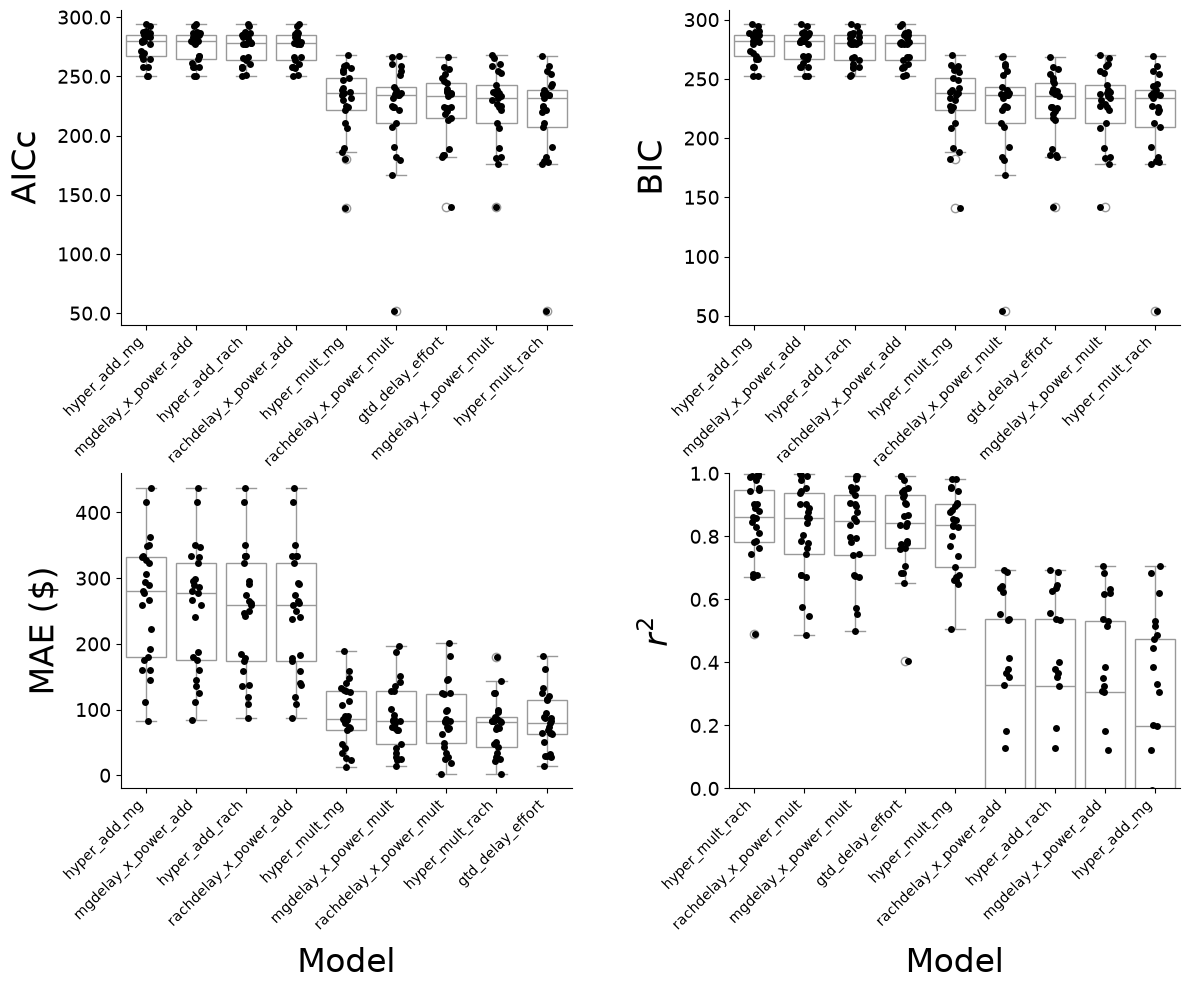

In [21]:
# Compute per-panel model order
#results_df = results_df.loc[~(results_df["r2"] < -10)]
# Highest -> Lowest along x-axis within each plot
order_aicc = (results_df.groupby('model')['aicc']
              .median()
              .sort_values(ascending=False)
              .index)

order_bic  = (results_df.groupby('model')['bic']
              .median()
              .sort_values(ascending=False)
              .index)

order_mae  = (results_df.groupby('model')['mae']
              .median()
              .sort_values(ascending=False)
              .index)

order_r2   = (results_df.groupby('model')['r2']
              .median()
              .sort_values(ascending=False)
              .index)

# Plot figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Top-left: AICc
ax = axes[0, 0]
sns.boxplot(
    x='model',
    y='aicc',
    data=results_df,
    order=order_aicc,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='aicc',
    data=results_df,
    order=order_aicc,
    color='k',
    ax=ax
)
ax.set_ylabel('AICc', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.1f}'))
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Top-right: BIC
ax = axes[0, 1]
sns.boxplot(
    x='model',
    y='bic',
    data=results_df,
    order=order_bic,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='bic',
    data=results_df,
    order=order_bic,
    color='k',
    ax=ax
)
ax.set_ylabel('BIC', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Bottom-left: MAE
ax = axes[1, 0]
sns.boxplot(
    x='model',
    y='mae',
    data=results_df,
    order=order_mae,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='mae',
    data=results_df,
    order=order_mae,
    color='k',
    ax=ax
)
ax.set_ylabel('MAE ($)', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Bottom-right: r^2
ax = axes[1, 1]
sns.boxplot(
    x='model',
    y='r2',
    data=results_df,
    order=order_r2,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='r2',
    data=results_df,
    order=order_r2,
    color='k',
    ax=ax
)
ax.set_ylabel(r'$r^2$', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
ax.set_ylim(0, 1)
sns.despine(ax=ax, top=True, right=True)

# Layout tweaks
plt.tight_layout()
plt.subplots_adjust(hspace=0.47, wspace=0.35)

# Run stats
print_friedman_and_posthoc(results_df, 'pid', 'model', 'aicc', 'AICc')
print_friedman_and_posthoc(results_df, 'pid', 'model', 'mae', 'MAE')

plt.show()

<Axes: xlabel='effort', ylabel='indiff_point'>

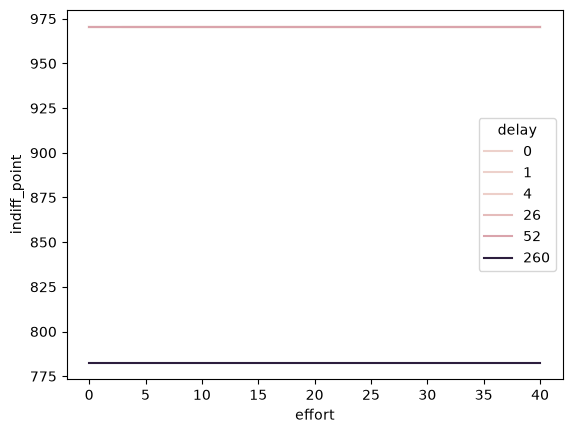

In [22]:
#trying to group participant 19 data
df[df["pid"]=="P19"]
p19_df = df[df["pid"]=="P19"]
p19_df.drop(columns=["question", "choice", "final_money"])

#plotting
sns.lineplot(data=p19_df, x="effort", y="indiff_point", hue="delay")


<Axes: xlabel='delay', ylabel='indiff_point'>

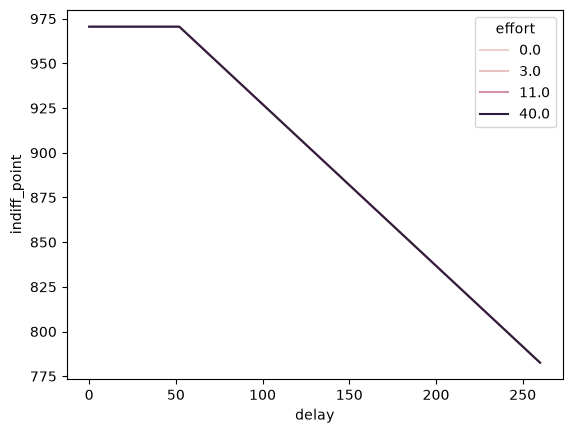

In [23]:
#plotting 19
sns.lineplot(data=p19_df, x="delay", y="indiff_point", hue="effort")

<Axes: xlabel='effort', ylabel='indiff_point'>

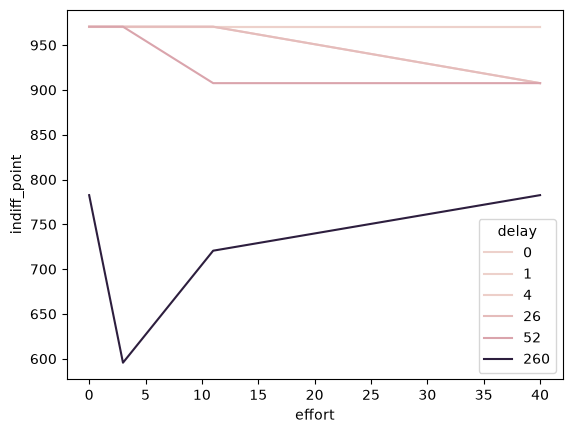

In [24]:
#trying to group participant 24 data
df[df["pid"]=="P24"]
p24_df = df[df["pid"]=="P24"]
p24_df.drop(columns=["question", "choice", "final_money"])

#plotting
sns.lineplot(data=p24_df, x="effort", y="indiff_point", hue="delay")

<Axes: xlabel='delay', ylabel='indiff_point'>

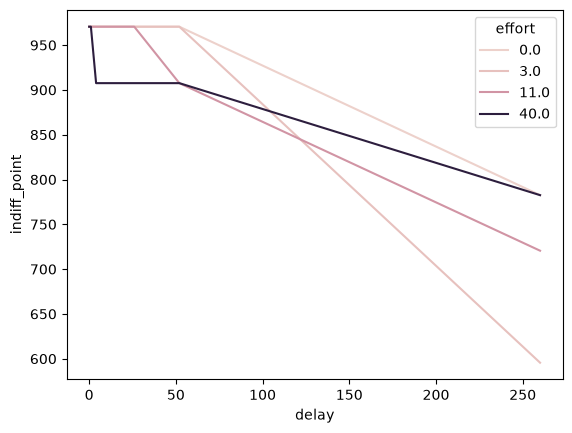

In [25]:
#plotting 24
sns.lineplot(data=p24_df, x="delay", y="indiff_point", hue="effort")

In [26]:
# Identify best model per PID by minimum AICc (across ALL models)
EPS = 1e-12

# Ensure key metric columns are numeric
metric_cols = ["mse", "aic", "aicc", "bic", "r2", "mae", "n_obs", "effort_mean"]
for c in metric_cols:
    if c in results_df.columns:
        results_df[c] = pd.to_numeric(results_df[c], errors="coerce")

# Guard MSE <= 0 (can create +/-inf AIC/BIC)
if "mse" in results_df.columns:
    results_df.loc[results_df["mse"] <= 0, "mse"] = EPS

# Drop rows without AICc (cannot rank those) + drop non-finite AICc
df_rank = results_df.dropna(subset=["aicc"]).copy()
df_rank = df_rank[np.isfinite(df_rank["aicc"])].copy()

# Verify same n_obs across models within each pid
if "n_obs" in df_rank.columns:
    nobs_check = df_rank.groupby("pid")["n_obs"].nunique()
    bad_pids = nobs_check[nobs_check > 1].index.tolist()
    if len(bad_pids) > 0:
        print(f"Warning: {len(bad_pids)} PIDs have differing n_obs across models (AICc comparability issue).")

# Compute delta AICc within pid (AICc - best AICc for that pid)
df_rank["best_aicc_pid"] = df_rank.groupby("pid")["aicc"].transform("min")
df_rank["delta_aicc"] = df_rank["aicc"] - df_rank["best_aicc_pid"]

# Akaike weights within pid
def _akaike_weights(delta_series: pd.Series) -> pd.Series:
    d = delta_series.to_numpy(dtype=float)
    w = np.exp(-0.5 * d)
    s = np.nansum(w)
    if s == 0 or np.isnan(s):
        return pd.Series([np.nan] * len(delta_series), index=delta_series.index)
    return pd.Series(w / s, index=delta_series.index)

df_rank["akaike_w"] = df_rank.groupby("pid")["delta_aicc"].transform(_akaike_weights)

# Pick the best model per pid (tie-breaker: lower BIC, then higher R2)
sort_cols = ["pid", "aicc"]
sort_asc  = [True, True]
if "bic" in df_rank.columns:
    sort_cols.append("bic")
    sort_asc.append(True)
if "r2" in df_rank.columns:
    sort_cols.append("r2")
    sort_asc.append(False)

df_rank_sorted = df_rank.sort_values(by=sort_cols, ascending=sort_asc)

best_cols = ["pid", "model", "aicc", "bic", "aic", "r2", "mae", "delta_aicc", "akaike_w", "n_obs", "effort_mean"]
best_cols = [c for c in best_cols if c in df_rank_sorted.columns]

best_by_pid = (
    df_rank_sorted.groupby("pid", as_index=False)
    .head(1)
    .loc[:, best_cols]
    .rename(columns={"model": "best_model", "aicc": "best_aicc"})
    .reset_index(drop=True)
)

# Create wide “scoreboards” per pid (AICc / delta / weight)
aicc_wide  = df_rank.pivot_table(index="pid", columns="model", values="aicc", aggfunc="first")
delta_wide = df_rank.pivot_table(index="pid", columns="model", values="delta_aicc", aggfunc="first")
w_wide     = df_rank.pivot_table(index="pid", columns="model", values="akaike_w", aggfunc="first")

# Add a leftmost quick-glance column naming the lowest-AICc model
aicc_wide.insert(
    0,
    "best_model_by_aicc",
    aicc_wide.idxmin(axis=1)
)

# Enforce consistent column order
model_order = [
    'hyper_mult_mg', 'hyper_add_mg',
    'hyper_mult_rach', 'hyper_add_rach',
    'mgprob_x_power_mult', 'mgprob_x_power_add',
    'rachprob_x_power_mult', 'rachprob_x_power_add',
    'gtd_prob_effort'
]

# Keep only models present
keep_models = [m for m in model_order if m in aicc_wide.columns]

# Reindex scoreboards
aicc_wide  = aicc_wide.reindex(columns=["best_model_by_aicc"] + keep_models)
delta_wide = delta_wide.reindex(columns=keep_models)
w_wide     = w_wide.reindex(columns=keep_models)

# Quick views
print("Best model by PID (top 10 by best AICc):")
print(best_by_pid.sort_values("best_aicc").head(10))

print("\nModel counts (how often each wins):")
print(best_by_pid["best_model"].value_counts(dropna=False))

Best model by PID (top 10 by best AICc):
    pid              best_model   best_aicc         bic         aic        r2  \
11  P19         hyper_mult_rach   51.969432   54.117492   48.440021  0.998952   
3   P11  rachdelay_x_power_mult  166.616530  168.764589  163.087118  0.995204   
6   P14         hyper_mult_rach  176.160501  178.308560  172.631089  0.988408   
17  P24         hyper_mult_rach  178.900515  181.048574  175.371103  0.862249   
22   P7  rachdelay_x_power_mult  181.924197  184.072256  178.394785  0.990012   
19   P4           hyper_mult_mg  189.630229  191.778288  186.100817  0.980463   
20   P5           hyper_mult_mg  206.525258  208.673317  202.995846  0.954953   
9   P17           hyper_mult_mg  210.646165  212.794225  207.116754  0.944123   
7   P15         hyper_mult_rach  219.899211  222.047271  216.369800  0.948114   
5   P13        gtd_delay_effort  220.313303  222.461363  216.783892  0.863112   

          mae  delta_aicc  akaike_w  n_obs  effort_mean  
11   1.67

In [27]:
# Pid x model AICc table, built straight from results_df.
# Column order (left to right) is the models' overall rank by median AICc
# across all participants -- lowest (best) median AICc on the left.
aicc_table = results_df.pivot_table(index="pid", columns="model", values="aicc", aggfunc="first")

model_rank_order = (
    results_df.groupby("model")["aicc"]
    .median()
    .sort_values(ascending=True)
    .index
)

aicc_table = aicc_table.reindex(columns=model_rank_order)
aicc_table = aicc_table.round(2)

aicc_table

model,hyper_mult_rach,mgdelay_x_power_mult,gtd_delay_effort,rachdelay_x_power_mult,hyper_mult_mg,rachdelay_x_power_add,hyper_add_rach,mgdelay_x_power_add,hyper_add_mg
pid,,,,,,,,,
P0,243.44,265.76,248.82,266.10,259.26,260.63,260.49,261.29,269.51
P1,223.87,224.36,224.42,223.87,224.33,278.06,278.06,279.67,279.67
P10,258.35,258.51,256.37,258.35,258.69,286.39,286.39,286.62,286.62
P11,178.01,176.37,183.51,166.62,248.35,277.19,277.63,280.95,284.37
P12,234.61,234.80,234.99,234.55,236.14,277.61,277.61,278.77,278.77
P13,221.15,221.21,220.31,221.15,221.39,284.82,284.82,284.60,284.60
P14,176.16,242.41,188.58,241.24,185.91,251.40,251.40,250.63,250.63
P15,219.90,226.45,223.46,223.94,238.32,278.81,278.87,278.86,282.78
P16,238.61,238.42,235.89,238.57,240.06,287.67,287.67,287.67,287.67


In [28]:
# Save the wide dfs
aicc_wide.to_csv("aicc_wide_1000.csv")
aicc_table.to_csv("aicc_table_1000.csv")
delta_wide.to_csv("delta_wide_1000.csv")
w_wide.to_csv("w_wide_1000.csv")

In [29]:
# Group means + SEM
df_plot = df.copy()
grouped_df = (
    df_plot.groupby(["effort", "delay"], as_index=False)["indiff_point"]
           .agg(indiff_point_mean="mean", indiff_point_sem="sem")
)
grouped_df["indiff_point_sem"] = grouped_df["indiff_point_sem"].fillna(0.0)

#O = grouped_df["odds_against"].to_numpy(dtype=float)
E = grouped_df["effort"].to_numpy(dtype=float)
D = grouped_df["delay"].to_numpy(dtype=float)
Y = grouped_df["indiff_point_mean"].to_numpy(dtype=float)
Y_sem = grouped_df["indiff_point_sem"].to_numpy(dtype=float)

X_dE = np.column_stack([D, E])
#p_from_O = np.column_stack([p, E])
#X_pE = np.column_stack([p_from_O, E])

# Mesh for plotting (axes always in O/E)
delay_grid = np.linspace(np.nanmin(D), np.nanmax(D), 60)
eff_grid  = np.linspace(np.nanmin(E), np.nanmax(E), 60)
D_mesh, E_mesh = np.meshgrid(delay_grid, eff_grid)

X_mesh_dE = np.column_stack([D_mesh.ravel(), E_mesh.ravel()])
#p_mesh    = 1.0 / (1.0 + O_mesh)
#X_mesh_pE = np.column_stack([p_mesh.ravel(), E_mesh.ravel()])


# Small wrappers to reuse earlier model primitives
def _wrap_combined_mult(delay_form: str, eff_form: str):
    def f(X, A, k, s_delay, gamma, s_eff):
        return combined_mult(X, A, k, s_delay, gamma, s_eff,
                             delay_form=delay_form, eff_form=eff_form)
    return f

def _wrap_combined_add(delay_form: str, eff_form: str):
    def f(X, A, k, s_delay, gamma, s_eff):
        return combined_add(X, A, k, s_delay, gamma, s_eff,
                            delay_form=delay_form, eff_form=eff_form)
    return f

# Unified model registry: (name, fn, xtype, param_names)
#   xtype = "OE" uses X[:,0]=odds_against, X[:,1]=effort
#   xtype = "pE" uses X[:,0]=p,          X[:,1]=effort
models = [
    ("MGd–MGe Add",   _wrap_combined_add("mg",   "mg"),   "dE", ["A","k","s_delay","gamma","s_eff"]),
    ("MGd–MGe Mult",  _wrap_combined_mult("mg",  "mg"),   "dE", ["A","k","s_delay","gamma","s_eff"]),
    ("Rd–Re Add",     _wrap_combined_add("rach", "rach"), "dE", ["A","k","s_delay","gamma","s_eff"]),
    ("Rd–Re Mult",    _wrap_combined_mult("rach","rach"), "dE", ["A","k","s_delay","gamma","s_eff"]),

    ("MGd–PE Add",    mgdelay_x_power_add,  "dE", ["A","k","s_delay","gamma_e","s_par"]),
    ("Rd–PE Add",     rachdelay_x_power_add,"dE", ["A","k","s_delay","gamma_e","s_par"]),

    ("MGd–PE Mult",   mgdelay_x_power_mult, "dE", ["A","k","s_delay","gamma_e","s_e"]),
    ("Rd–PE Mult",    rachdelay_x_power_mult,"dE",["A","k","s_delay","gamma_e","s_e"]),

    ("GTD",            gtd_delay_effort, "dE", ["A","alpha","kappa","gamma","beta"]),
]


<>:175: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:175: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/var/folders/bn/q2_h4fgd1f17lvc575n4j9m40000gn/T/ipykernel_54809/2350122640.py:175: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  f"$r^2$={fs['r2']:.2f}, MAE=\${fs['mae']:.2f}"


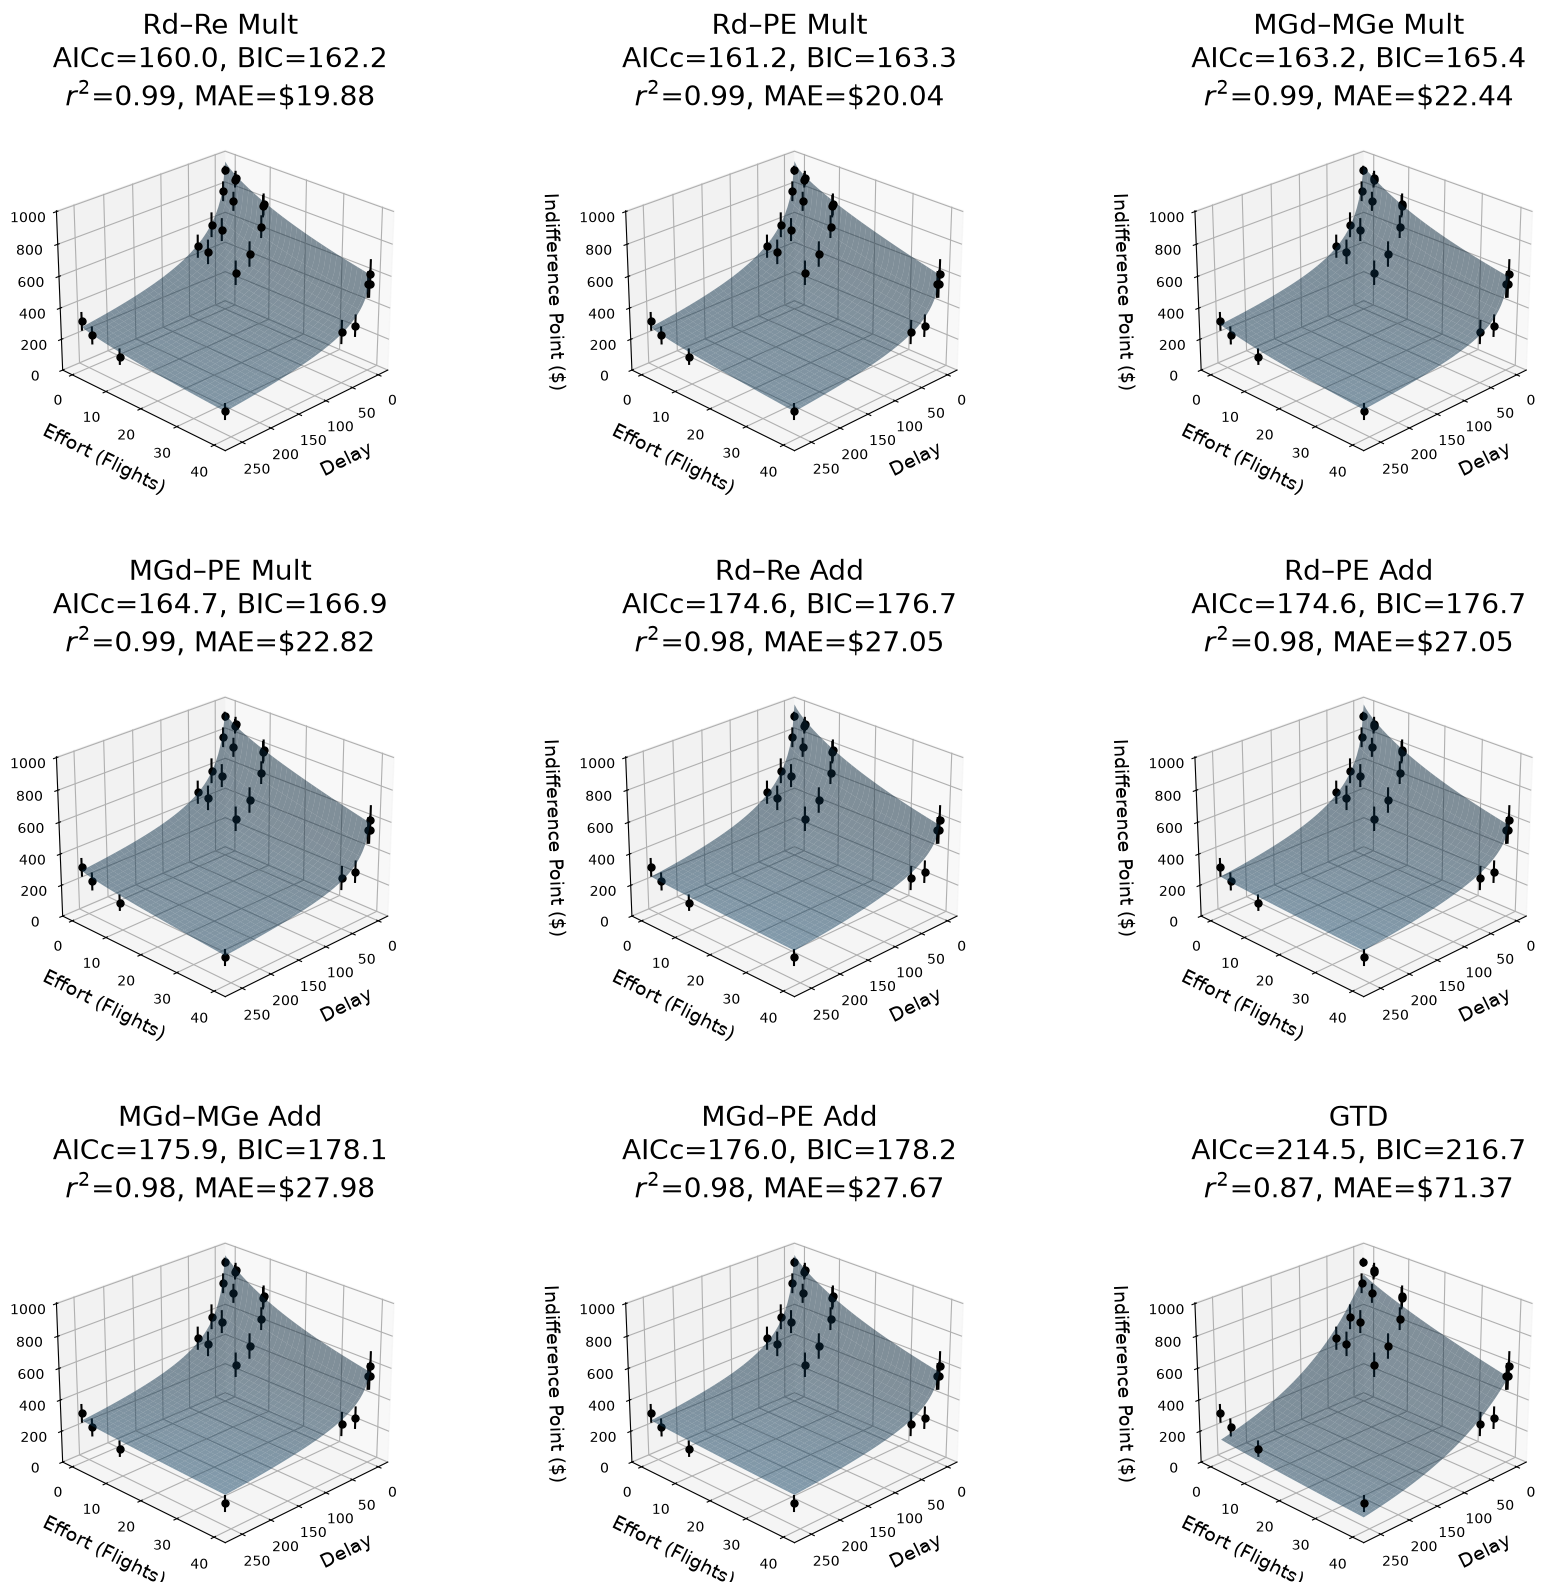

In [30]:
# Starts + bounds
A_init = float(np.nanmax(Y))

A_bounds      = (1e-6, 2000.0)
k_bounds      = (1e-6, 50.0)
sdelay_bounds  = (1e-3, 6.0)
gamma_bounds  = (1e-6, 50.0)
seff_bounds   = (1e-3, 6.0)

kE_bounds     = (1e-9, 50.0)
spar_bounds   = (0.25, 6.0)

gamma_e_bounds = (0.0, 1.0)
s_e_bounds     = (0.25, 6.0)

alpha_bounds   = (1e-3, 5.0)
kappa_bounds   = (1e-6, 10.0)
#g_prelec_bounds= (1e-3, 5.0)
kE_gtd_bounds  = (1e-6, 10.0)
beta_bounds    = (1e-3, 5.0)

bounds_by_param = {
    "A":       A_bounds,
    "k":       k_bounds,
    "s_delay":  sdelay_bounds,
    "gamma":   gamma_bounds,
    "s_eff":   seff_bounds,
    "kE":      kE_bounds,
    "s_par":   spar_bounds,
    "gamma_e": gamma_e_bounds,
    "s_e":     s_e_bounds,
    "alpha":   alpha_bounds,
    "kappa":   kappa_bounds,
    #"gammaP":  g_prelec_bounds,
    "beta":    beta_bounds,
}

# Start guesses
p0_by_param = {
    "A":       A_init,
    "k":       1.0,
    "s_delay":  1.0,
    "gamma":   1.0,
    "s_eff":   1.0,
    "kE":      0.01,
    "s_par":   2.0,
    "gamma_e": 0.001,
    "s_e":     2.0,
    "alpha":   0.5,
    "kappa":   0.3,
    #"gammaP":  0.8,
    "beta":    0.5,
}

def get_p0_and_bounds_from_param_list(param_names): #check this block with David; where is param_names
     p0 = []
     lb = []
     ub = []
     for p in param_names:
         if p == "gamma_e":
#                 #take out below since no weighting function
            if "alpha" in param_names and "kappa" in param_names:
                 lo, hi = kappa_bounds
                 p0.append(p0_by_param["kappa"])
            else:
                 lo, hi = gamma_bounds
                 p0.append(p0_by_param["gamma"])
         elif p == "kE" and ("alpha" in param_names and "kappa" in param_names):
                 lo, hi = kE_gtd_bounds
                 p0.append(0.1)
         else:
             lo, hi = bounds_by_param[p]
             p0.append(p0_by_param[p])
         lb.append(lo)
         ub.append(hi)
     return p0, (lb, ub)


# Fit ALL models, compute AIC/AICc/BIC, sort by AICc
fit_summaries = []
n = int(len(Y))

for mname, mfn, xtype, param_names in models:
    X_fit = X_dE #if xtype == "dE" else X_pE
    p0, bounds = get_p0_and_bounds_from_param_list(param_names)

    try:
        params, _ = curve_fit(
            mfn, X_fit, Y,
            p0=p0,
            bounds=bounds,
            maxfev=200000
        )

        Yhat = mfn(X_fit, *params)
        resid = (Y - Yhat)
        rss = float(np.nansum(resid ** 2))
        k = int(len(params))

        fit_summaries.append({
            "name": mname,
            "fn": mfn,
            "xtype": xtype,
            "param_names": param_names,
            "params": params,
            "r2": float(r2_score(Y, Yhat)),
            "mae": float(mean_absolute_error(Y, Yhat)),
            "rss": rss,
            "aicc": float(compute_aicc_from_rss(n, rss, k)),
            "bic": float(compute_bic_from_rss(n, rss, k)),
            "aic": float(compute_aic_from_rss(n, rss, k)),
        })

    except Exception as e:
        fit_summaries.append({
            "name": mname,
            "fn": mfn,
            "xtype": xtype,
            "param_names": param_names,
            "params": None,
            "r2": np.nan,
            "mae": np.nan,
            "rss": np.nan,
            "aicc": np.inf,
            "bic": np.inf,
            "aic": np.inf,
            "error": str(e),
        })

fit_summaries = sorted(fit_summaries, key=lambda d: d["aicc"])


# Plot in sorted order (top-left to bottom-right)
fig = plt.figure(figsize=(18, 16))
plt.subplots_adjust(left=0.06, right=0.98, bottom=0.04, top=0.95, hspace=0.38, wspace=0.10)

ELEV = 25
AZIM = 45
SURF_ALPHA = 0.5

for i, fs in enumerate(fit_summaries, start=1):
    ax = fig.add_subplot(3, 3, i, projection="3d")

    mname  = fs["name"]
    xtype  = fs["xtype"]
    mfn    = fs["fn"]
    params = fs["params"]

    ax.set_xlabel("Delay", labelpad=8, fontsize=14)
    ax.set_ylabel("Effort (Flights)", labelpad=8, fontsize=14)
    ax.set_zlabel("Indifference Point ($)", labelpad=10, fontsize=14)

    ax.view_init(elev=ELEV, azim=AZIM)
    ax.set_zlim(0, max(1005, np.nanmax(Y) * 1.05))

    # Points + SEM bars
    ax.scatter(D, E, Y, c="k", s=25, depthshade=False)
    for x_, y_, z_, sem_ in zip(D, E, Y, Y_sem):
        if sem_ > 0:
            ax.plot([x_, x_], [y_, y_], [z_ - sem_, z_ + sem_], c="k", linewidth=1.5)

    # Surface
    if params is not None:
        if xtype == "DE":
            Z = mfn(X_mesh_dE, *params).reshape(D_mesh.shape)
        else:
            Z = mfn(X_mesh_dE, *params).reshape(D_mesh.shape)

        Z = np.where(np.isfinite(Z), Z, np.nan)
        ax.plot_surface(D_mesh, E_mesh, Z, alpha=SURF_ALPHA, linewidth=0, antialiased=True)

        title = (
            f"{mname}\n"
            f"AICc={fs['aicc']:.1f}, BIC={fs['bic']:.1f}\n"
            f"$r^2$={fs['r2']:.2f}, MAE=\${fs['mae']:.2f}"
        )
    else:
        title = f"{mname}\nFIT FAILED"

    ax.set_title(title, fontsize=20)

plt.subplots_adjust(hspace=0.5)
plt.show()


In [31]:
# Build Table with results
model_order = [
    "hyper_mult_mg",
    "hyper_add_mg",
    "hyper_mult_rach",
    "hyper_add_rach",
    "mgprob_x_power_mult",
    "mgprob_x_power_add",
    "rachprob_x_power_mult",
    "rachprob_x_power_add",
    "gtd_prob_effort",
]

# Keep only models present in df_rank
models_present = set(df_rank["model"].unique())
models = [m for m in model_order if m in models_present]

# Ensure numeric
for c in ["aic", "aicc", "bic", "r2", "mae"]:
    if c in df_rank.columns:
        df_rank[c] = pd.to_numeric(df_rank[c], errors="coerce")

# Pivot metrics wide: columns like "r2 hyper_mult_mg", etc.
metrics = ["aicc", "bic", "mae", "r2"]
wide = (
    df_rank[df_rank["model"].isin(models)]
    .pivot_table(index="pid", columns="model", values=metrics, aggfunc="first")
)

# Flatten MultiIndex columns -> "r2 hyper_mult_mg"
wide.columns = [f"{metric} {model}" for metric, model in wide.columns]
wide = wide.reset_index()

# Best model among included models (min AICc)
aicc_cols = [f"aicc {m}" for m in models if f"aicc {m}" in wide.columns]
wide["Best Model"] = wide[aicc_cols].idxmin(axis=1).str.replace("aicc ", "", regex=False)
wide["Best AICc"] = wide[aicc_cols].min(axis=1)

# Difference in AICc relative to best per PID
for m in models:
    col = f"aicc {m}"
    if col in wide.columns:
        wide[f"delta-AICc {m}"] = wide[col] - wide["Best AICc"]

# Column ordering: PID, then metrics grouped by model, then Best Model, then ΔAICc block
ordered_cols = ["pid"]

# metric blocks per model (r2, mae, aicc, bic)
for metric in ["r2", "mae", "aicc", "bic"]:
    for m in models:
        col = f"{metric} {m}"
        if col in wide.columns:
            ordered_cols.append(col)

ordered_cols += ["Best Model", "Best AICc"]

# Deltas at the end
for m in models:
    col = f"delta-AICc {m}"
    if col in wide.columns:
        ordered_cols.append(col)

table_df = wide[ordered_cols].copy()

# Round for presentation
round_map = {}
for m in models:
    if f"r2 {m}" in table_df.columns:
        round_map[f"r2 {m}"] = 2
    if f"mae {m}" in table_df.columns:
        round_map[f"mae {m}"] = 2
    if f"aicc {m}" in table_df.columns:
        round_map[f"aicc {m}"] = 2
    if f"bic {m}" in table_df.columns:
        round_map[f"bic {m}"] = 2

if "Best AICc" in table_df.columns:
    round_map["Best AICc"] = 2

table_df = table_df.round(round_map)

# Export / view
table_df.to_csv("model_comparison_table_1000.csv", index=False)


In [32]:
table_df

,pid,r2 hyper_mult_mg,r2 hyper_add_mg,r2 hyper_mult_rach,r2 hyper_add_rach,mae hyper_mult_mg,mae hyper_add_mg,mae hyper_mult_rach,mae hyper_add_rach,aicc hyper_mult_mg,...,bic hyper_mult_mg,bic hyper_add_mg,bic hyper_mult_rach,bic hyper_add_rach,Best Model,Best AICc,delta-AICc hyper_mult_mg,delta-AICc hyper_add_mg,delta-AICc hyper_mult_rach,delta-AICc hyper_add_rach
0,P0,0.66,0.47,0.83,0.64,158.85,192.38,87.94,136.01,259.26,...,261.41,271.66,245.59,262.63,hyper_mult_rach,243.44,15.819242,26.072733,0.000000,17.045655
1,P1,0.90,-0.09,0.90,-0.01,73.28,280.20,72.78,259.25,224.33,...,226.48,281.82,226.02,280.21,hyper_mult_rach,223.87,0.456123,55.795221,0.000000,54.189503
2,P10,0.74,0.12,0.74,0.13,128.48,323.37,125.17,323.15,258.69,...,260.84,288.76,260.50,288.53,hyper_mult_rach,258.35,0.339552,28.264448,0.000000,28.033668
3,P11,0.83,0.20,0.99,0.40,133.55,327.01,26.40,247.60,248.35,...,250.50,286.51,180.16,279.78,hyper_mult_rach,178.01,70.339744,106.353809,0.000000,99.615096
4,P12,0.77,-0.47,0.78,-0.40,89.98,290.28,83.02,274.40,236.14,...,238.28,280.91,236.76,279.75,hyper_mult_rach,234.61,1.523535,44.153900,0.000000,42.992827
5,P13,0.86,-1.24,0.86,-1.26,69.09,331.58,69.80,334.11,221.39,...,223.53,286.74,223.29,286.97,hyper_mult_rach,221.15,0.240076,63.450012,0.000000,63.674367
6,P14,0.98,0.70,0.99,0.69,26.42,83.24,21.33,87.47,185.91,...,188.06,252.78,178.31,253.55,hyper_mult_rach,176.16,9.751775,74.467921,0.000000,75.241268
7,P15,0.88,0.20,0.95,0.33,112.69,294.51,50.07,243.17,238.32,...,240.47,284.92,222.05,281.02,hyper_mult_rach,219.90,18.420686,62.876544,0.000000,58.973675
8,P16,0.65,-1.78,0.67,-1.78,106.70,350.14,99.51,350.14,240.06,...,242.21,289.82,240.76,289.82,hyper_mult_rach,238.61,1.455229,49.064761,0.000000,49.064797
9,P17,0.94,0.68,0.94,0.69,47.35,112.14,48.31,108.48,210.65,...,212.79,252.66,212.90,252.46,hyper_mult_mg,210.65,0.000000,39.867296,0.102796,39.663368


In [33]:
thou_task_dem = pd.read_excel("$1000 Task Demographics.xlsx")

In [34]:
(thou_task_dem["Age Range"] == "18-24").sum()


np.int64(0)